# Single-hidden-layer MLP

The tutorial's sparse MLP (one hidden layer) on token indicators and on bag of words, evaluated with cross-validation on SST-2 train.

In [1]:
TOKENIZERS = ["nltk", "bpe_500", "bpe_2000", "bpe_8000", "bpe_20000"]  # the first one is the baseline in the comparison
SEEDS = [0]            # one cross-validation run per seed, e.g. [0, 3, 5]
K = 5                  # number of folds
MIN_WORDS = 1          # drop train examples with fewer words (1 keeps all; SST-2 train has many short phrases)
MLP_ARGS = dict(hidden_dim=32, dropout=0.3, batch_size=64, learning_rate=1e-4, weight_decay=1e-2, num_epochs=10)
ROPE = 0.005  # two systems count as practically equivalent if their mean accuracy differs by less than this
CV = "parents"  # "parents": held-out folds are whole parent sentences (leak-free); "random": plain random folds
SUFFIX = "" if CV == "random" else "_parents"  # appended to the names of the saved results
FEATURES = ["indicator", "bow", "glove"]  # glove: averaged GloVe embeddings, only available with the nltk tokenizer
RECOMPUTE = False  # True: ignore saved results and recompute everything


In [2]:
import warnings
from sklearn.exceptions import ConvergenceWarning

warnings.filterwarnings("ignore", category=ConvergenceWarning)
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd

import cv_helpers as cv
from tokenized_data import load

## Cross-validation
For each tokenizer and each representation (token indicators, bag of words): k-fold cross-validation on the train split, repeated for every seed. Accuracies are saved to `results/` for the Bayesian comparison later.

`CV = "parents"` (default): the held-out fold is a random set of whole parent sentences (rows that are not inside a longer row, see `data_analysis.ipynb`). Training uses every other row except those equal to, or inside, a held-out sentence, so the model never sees any part of the text it is tested on. `CV = "random"` gives plain random folds, which leak because sub-phrases of a held-out phrase's sentence are in training.

**Epoch choice.** In every fold the MLP trains for `num_epochs` epochs. The epoch that is reported is chosen by accuracy on an inner validation slice: 10% of the fold's training sentences (whole parent sentences with parent folds, with their pieces removed from the rows the model trains on). The held-out sentences are scored once, at that epoch, and play no part in the choice. The tutorial instead picks the epoch with the lowest held-out loss, which uses the scored data and, as the curves below show, often picks a poor epoch.

**Representations.** `indicator` and `bow` are the sparse token features. `glove` is the mean of the GloVe embeddings (6B tokens, 300 dimensions; Pennington, Socher & Manning, 2014) of a sentence's NLTK tokens, standardised with the mean and spread of the training rows. It only exists for the `nltk` tokenizer, because GloVe has vectors for words, not for BPE pieces. Finished runs are reused from `results/` unless `RECOMPUTE = True`.

In [3]:
# raw sentences of the train rows (the same for every tokenizer), used to find the parent sentences
raw_train_text = load("bpe_500")[0]["train"].text.tolist()
inner_texts = raw_train_text if CV == "parents" else None  # the inner validation slice is built from whole parent sentences

def get_folds(y, seed):
    if CV == "parents":
        assert MIN_WORDS == 1, "parent folds use all train rows"
        return cv.parent_folds(raw_train_text, y, K, seed)
    return cv.make_folds(y, K, seed)

results = {}
n_examples = {}

for tok_name in TOKENIZERS:
    splits, tokenizer = load(tok_name)
    train = splits["train"]
    train = train[train.text.str.split().str.len() >= MIN_WORDS]
    y = train.label.to_numpy()
    print(f"{tok_name}: {len(train)} examples, vocabulary {tokenizer.get_vocab_size()}")
    n_examples[tok_name] = len(train)

    for features in cv.features_for(tok_name, FEATURES):
        name = f"mlp_{features}_{tok_name}{SUFFIX}"
        info = dict(tokenizer=tok_name, model="mlp", features=features, seeds=SEEDS, k=K,
                    min_words=MIN_WORDS, cv=CV, mlp_args=MLP_ARGS)
        accuracies = None if RECOMPUTE else cv.cached_results(name, require=["chosen_epochs"], **info)
        if accuracies is None:
            X, scale = cv.build_features(train, tokenizer, features)
            epochs = []  # the epoch chosen in every fold
            accuracies = [cv.cv_mlp(X, y, get_folds(y, seed), texts=inner_texts, seed=seed, epochs_out=epochs,
                                    scale=scale, **MLP_ARGS) for seed in SEEDS]
            cv.save_results(name, accuracies, chosen_epochs=epochs, **info)
        else:
            print(f"  {features}: saved results")
        results[(tok_name, features)] = np.array(accuracies)  # shape [seeds, folds]

nltk: 67349 examples, vocabulary 14802
  indicator: saved results
  bow: saved results
  glove: saved results


bpe_500: 67349 examples, vocabulary 500
  indicator: saved results
  bow: saved results


bpe_2000: 67349 examples, vocabulary 2000
  indicator: saved results
  bow: saved results


bpe_8000: 67349 examples, vocabulary 8000
  indicator: saved results
  bow: saved results


bpe_20000: 67349 examples, vocabulary 20000
  indicator: saved results
  bow: saved results


## Results

In [4]:
pd.DataFrame([
    {"tokenizer": t, "features": f, "mean accuracy": a.mean(), "std": a.std(), "scores": a.size}
    for (t, f), a in results.items()
]).round(4)

,tokenizer,features,mean accuracy,std,scores
0,nltk,indicator,0.8109,0.0138,5
1,nltk,bow,0.8081,0.0127,5
2,nltk,glove,0.7884,0.0080,5
3,bpe_500,indicator,0.7066,0.0112,5
4,bpe_500,bow,0.7160,0.0108,5
5,bpe_2000,indicator,0.7657,0.0111,5
6,bpe_2000,bow,0.7683,0.0102,5
7,bpe_8000,indicator,0.8064,0.0123,5
8,bpe_8000,bow,0.8042,0.0146,5
9,bpe_20000,indicator,0.8089,0.0077,5


## Compare tokenizers and representations
Fold accuracies of every system, then pairwise Bayesian comparisons (correlated t-test, as in the tutorial) with a ROPE of `ROPE` accuracy. Folds are identical across systems, so the scores are paired.
`P(A wins)`, `P(tie)` and `P(B wins)` are the posterior probabilities that the true mean difference lies left of, inside, or right of the ROPE.

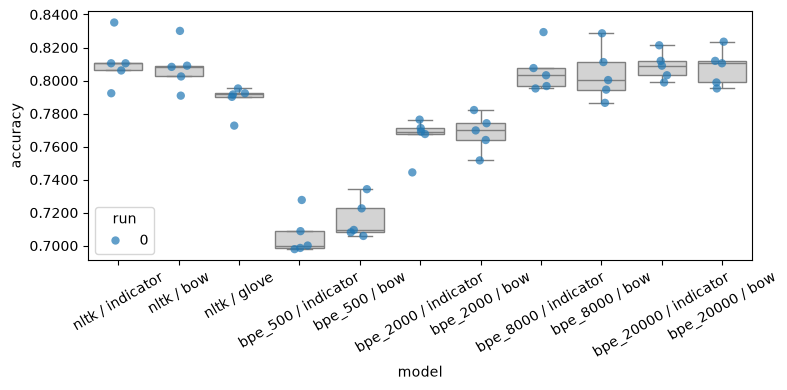

In [5]:
from from_tutorial import analysis

assert len(set(n_examples.values())) == 1, "tokenizers must be evaluated on the same examples"

scores = pd.DataFrame([
    {"model": f"{t} / {f}", "accuracy": acc, "run": run, "fold": fold}
    for (t, f), accs in results.items()
    for run, row in enumerate(accs)
    for fold, acc in enumerate(row)
])
analysis.plot_box_and_points(scores)

In [6]:
def compare(a, b):
    posterior = analysis.BenavoliCorrelatedT(results[a].flatten(), results[b].flatten(), runs=len(SEEDS))
    p_a, p_tie, p_b = posterior.probs(ROPE)
    return {"A": " / ".join(a), "B": " / ".join(b), "mean diff (B-A)": posterior.mean_diff,
            "P(A wins)": p_a, "P(tie)": p_tie, "P(B wins)": p_b}

rows = []
# each tokenizer against the baseline tokenizer, per representation
for features in ["indicator", "bow"]:
    for tok_name in TOKENIZERS[1:]:
        rows.append(compare((TOKENIZERS[0], features), (tok_name, features)))
# token indicators against bag of words, per tokenizer
for tok_name in TOKENIZERS:
    rows.append(compare((tok_name, "indicator"), (tok_name, "bow")))

# averaged GloVe embeddings against the sparse representations (NLTK tokens only)
if ("nltk", "glove") in results:
    for features in ["indicator", "bow"]:
        rows.append(compare(("nltk", features), ("nltk", "glove")))

pd.DataFrame(rows).round(3)

,A,B,mean diff (B-A),P(A wins),P(tie),P(B wins)
0,nltk / indicator,bpe_500 / indicator,-0.104,0.999,0.000,0.001
1,nltk / indicator,bpe_2000 / indicator,-0.045,0.987,0.007,0.006
2,nltk / indicator,bpe_8000 / indicator,-0.005,0.476,0.382,0.142
3,nltk / indicator,bpe_20000 / indicator,-0.002,0.294,0.589,0.117
4,nltk / bow,bpe_500 / bow,-0.092,1.000,0.000,0.000
5,nltk / bow,bpe_2000 / bow,-0.040,0.986,0.008,0.006
6,nltk / bow,bpe_8000 / bow,-0.004,0.449,0.388,0.163
7,nltk / bow,bpe_20000 / bow,-0.000,0.099,0.813,0.089
8,nltk / indicator,nltk / bow,-0.003,0.388,0.436,0.176
9,bpe_500 / indicator,bpe_500 / bow,0.009,0.048,0.223,0.730


## Evaluation on the validation split
Every system is trained once on all of train and scored once on the SST-2 validation split (whole sentences that never appear in train). This is the most honest estimate of real performance. The table puts it next to the cross-validation scores with random folds and with parent folds; the gap shows how much leakage inflates each cross-validation. Validation accuracies are cached in `results/`. The MLP's epoch is chosen the same way as in the cross-validation, on an inner slice of the train sentences, never on the validation split.

In [7]:
PREFIX = "mlp"

def mean_cv(name):
    try:
        return cv.load_results(name).mean()
    except FileNotFoundError:
        return float("nan")

rows = []
for tok_name in TOKENIZERS:
    splits, tokenizer = load(tok_name)
    train = splits["train"]
    train = train[train.text.str.split().str.len() >= MIN_WORDS]
    validation = splits["validation"]
    y_train, y_val = train.label.to_numpy(), validation.label.to_numpy()

    for features in cv.features_for(tok_name, FEATURES):
        name = f"{PREFIX}_{features}_{tok_name}"
        try:
            validation_accuracy = cv.load_results(name + "_validation").item()   # cached
        except FileNotFoundError:
            X_train, scale = cv.build_features(train, tokenizer, features)
            X_val, _ = cv.build_features(validation, tokenizer, features)
            validation_accuracy = np.mean([
                cv.eval_mlp(X_train, y_train, X_val, y_val, texts=inner_texts, seed=seed, scale=scale, **MLP_ARGS)
                for seed in SEEDS
            ])
            cv.save_results(name + "_validation", [[validation_accuracy]], tokenizer=tok_name, model=PREFIX,
                            features=features, min_words=MIN_WORDS, seeds=SEEDS, mlp_args=MLP_ARGS)
        rows.append({
            "tokenizer": tok_name, "features": features,
            "cv random folds": mean_cv(name),
            "cv parent folds": mean_cv(name + "_parents"),
            "validation": validation_accuracy,
        })

table = pd.DataFrame(rows)
table["gap random"] = table["cv random folds"] - table["validation"]
table["gap parents"] = table["cv parent folds"] - table["validation"]
print(f"majority-class baseline on validation: {max(y_val.mean(), 1 - y_val.mean()):.4f}")
table.round(4)

/home/amitai/Uva/Master1/NLP/nlp1_project1_group24/from_tutorial/smlp.py:68: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at /__w/pytorch/pytorch/torch/csrc/utils/tensor_new.cpp:252.)
  indices = torch.tensor([x.row, x.col], dtype=torch.long)
/home/amitai/Uva/Master1/NLP/nlp1_project1_group24/from_tutorial/smlp.py:71: UserWarning: Sparse invariant checks are implicitly disabled. Memory errors (e.g. SEGFAULT) will occur when operating on a sparse tensor which violates the invariants, but checks incur performance overhead. To silence this warning, explicitly opt in or out. See `torch.sparse.check_sparse_tensor_invariants.__doc__` for guidance.  (Triggered internally at /__w/pytorch/pytorch/aten/src/ATen/Context.cpp:848.)
  return torch.sparse_coo_tensor(indices, values, size=x.shape).coalesce()


majority-class baseline on validation: 0.5092


,tokenizer,features,cv random folds,cv parent folds,validation,gap random,gap parents
0,nltk,indicator,0.9098,0.8109,0.8211,0.0887,-0.0102
1,nltk,bow,0.9100,0.8081,0.8280,0.0821,-0.0198
2,nltk,glove,NaN,0.7884,0.7752,NaN,0.0132
3,bpe_500,indicator,0.7944,0.7066,0.7523,0.0421,-0.0457
4,bpe_500,bow,0.7984,0.7160,0.7443,0.0542,-0.0282
5,bpe_2000,indicator,0.8648,0.7657,0.7936,0.0712,-0.0279
6,bpe_2000,bow,0.8665,0.7683,0.7924,0.0741,-0.0241
7,bpe_8000,indicator,0.9026,0.8064,0.8303,0.0723,-0.0239
8,bpe_8000,bow,0.9037,0.8042,0.8360,0.0677,-0.0318
9,bpe_20000,indicator,0.9088,0.8089,0.8257,0.0831,-0.0168


## Training curves
Loss and accuracy after every epoch for the first cross-validation fold, one panel per tokenizer. Solid lines are the held-out sentences, dashed lines the rows the model trains on (averaged over the epoch, with dropout on). The dotted vertical line is the epoch chosen on the inner validation slice, which is the epoch the cross-validation reports. Curves are cached in `results/`.

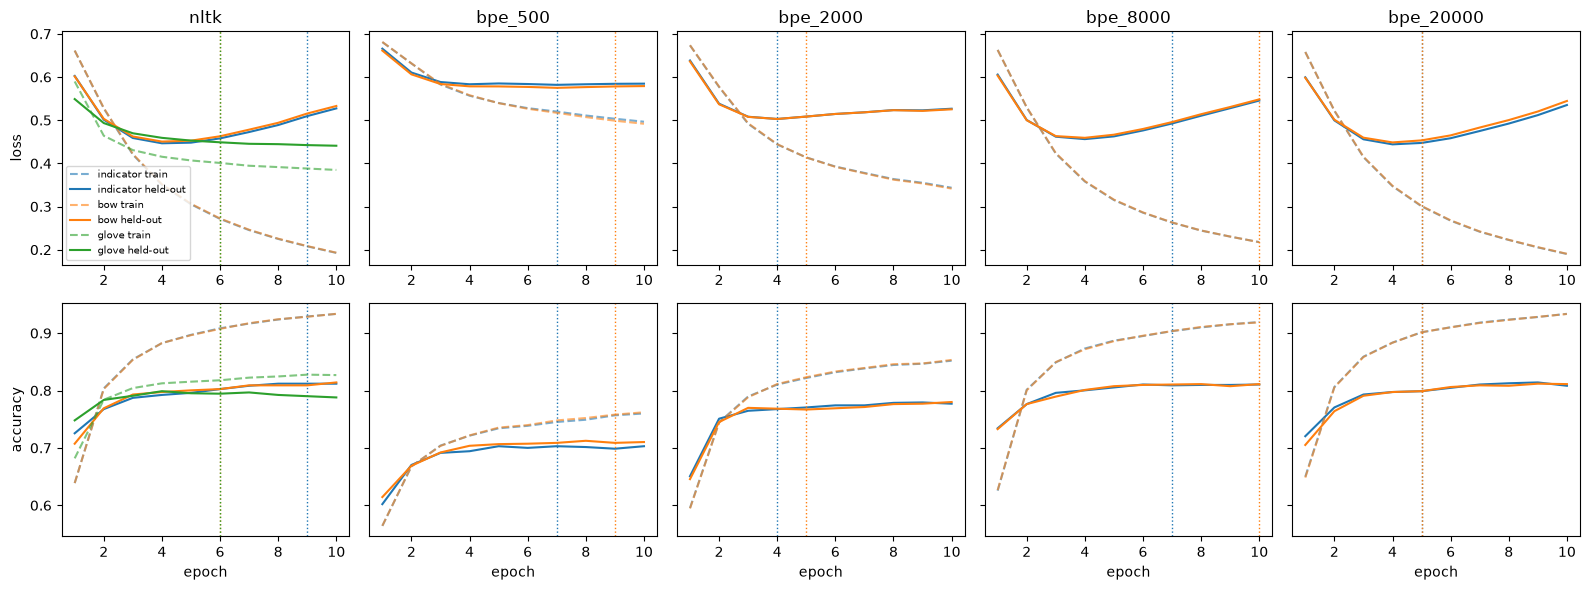

In [8]:
import json
import matplotlib.pyplot as plt

curve_file = cv.RESULTS_DIR / f"mlp_curves{SUFFIX}.json"
curves = json.loads(curve_file.read_text()) if curve_file.exists() else {}
settings = dict(MLP_ARGS, seed=SEEDS[0], k=K, cv=CV, epoch_choice="inner validation")
if curves.get("_settings") != settings:
    curves = {"_settings": settings}   # settings changed: recompute

raw_text = load("bpe_500")[0]["train"].text.tolist()

for tok_name in TOKENIZERS:
    splits, tokenizer = load(tok_name)
    y = splits["train"].label.to_numpy()
    folds = cv.parent_folds(raw_text, y, K, SEEDS[0]) if CV == "parents" else cv.make_folds(y, K, SEEDS[0])
    train_idx, heldout_idx = folds[0]
    for features in cv.features_for(tok_name, FEATURES):
        key = f"{tok_name}/{features}"
        if key not in curves:
            X, scale = cv.build_features(splits["train"], tokenizer, features)
            curves[key] = cv.mlp_curve(X, y, train_idx, heldout_idx, texts=inner_texts, seed=SEEDS[0], scale=scale, **MLP_ARGS)
            curve_file.write_text(json.dumps(curves))

fig, axes = plt.subplots(2, len(TOKENIZERS), figsize=(3.2 * len(TOKENIZERS), 6), sharey="row")
for col, tok_name in enumerate(TOKENIZERS):
    for features, color in [("indicator", "tab:blue"), ("bow", "tab:orange"), ("glove", "tab:green")]:
        if f"{tok_name}/{features}" not in curves:
            continue
        history = curves[f"{tok_name}/{features}"]
        epochs = np.arange(1, len(history) + 1)
        for row, metric in enumerate(["loss", "accuracy"]):
            axes[row, col].plot(epochs, [h["train"][metric] for h in history], "--", color=color, alpha=0.6, label=f"{features} train")
            axes[row, col].plot(epochs, [h["heldout"][metric] for h in history], "-", color=color, label=f"{features} held-out")
        best = int(np.argmax([h["select"]["accuracy"] for h in history]))   # first epoch with the best inner-validation accuracy
        axes[0, col].axvline(best + 1, color=color, ls=":", lw=1)
        axes[1, col].axvline(best + 1, color=color, ls=":", lw=1)
    axes[0, col].set_title(tok_name)
    axes[1, col].set_xlabel("epoch")
axes[0, 0].set_ylabel("loss")
axes[1, 0].set_ylabel("accuracy")
axes[0, 0].legend(fontsize=7)
plt.tight_layout()
plt.show()

In [9]:
pd.DataFrame([
    {
        "tokenizer": key.split("/")[0], "features": key.split("/")[1],
        "chosen epoch (inner validation)": int(np.argmax([h["select"]["accuracy"] for h in history])) + 1,
        "held-out accuracy at chosen epoch": history[int(np.argmax([h["select"]["accuracy"] for h in history]))]["heldout"]["accuracy"],
        "held-out accuracy at last epoch": history[-1]["heldout"]["accuracy"],
        "best held-out accuracy (any epoch)": max(h["heldout"]["accuracy"] for h in history),
    }
    for key, history in curves.items() if key != "_settings"
]).round(4)

,tokenizer,features,chosen epoch (inner validation),held-out accuracy at chosen epoch,held-out accuracy at last epoch,best held-out accuracy (any epoch)
0,nltk,indicator,9,0.8119,0.8119,0.8119
1,nltk,bow,6,0.8025,0.8141,0.8141
2,bpe_500,indicator,7,0.7030,0.7030,0.7030
3,bpe_500,bow,9,0.7088,0.7102,0.7124
4,bpe_2000,indicator,4,0.7676,0.7771,0.7792
5,bpe_2000,bow,5,0.7669,0.7800,0.7800
6,bpe_8000,indicator,7,0.8090,0.8105,0.8105
7,bpe_8000,bow,10,0.8112,0.8112,0.8112
8,bpe_20000,indicator,5,0.7988,0.8083,0.8141
9,bpe_20000,bow,5,0.7988,0.8112,0.8119
